In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

In [16]:
df = pd.read_csv("Waves_2023.txt", sep=r"\s+")
df[["WVHT", "DPD", "APD", "MWD", "WTMP"]].head()

,WVHT,DPD,APD,MWD,WTMP
0,1.12,12.50,7.69,269,15.3
1,1.16,11.76,7.34,272,15.3
2,1.20,12.50,7.08,268,15.3
3,1.25,10.53,7.33,268,15.4
4,1.27,10.53,7.57,268,15.5


In [10]:
X = df[["DPD", "APD", "MWD", "WTMP"]]
y = df["WVHT"]
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.25, random_state=42)

In [11]:
models = {"Linear regression": LinearRegression(), "Decision tree": DecisionTreeRegressor(criterion="squared_error", random_state=42), "Random forest (25)": RandomForestRegressor(n_estimators=25, criterion="squared_error", random_state=42)}
results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    results.append({"Model": name, "Train RMSE (m)": np.sqrt(mean_squared_error(y_train, model.predict(X_train))), "Validation RMSE (m)": np.sqrt(mean_squared_error(y_val, model.predict(X_val))), "Test RMSE (m)": np.sqrt(mean_squared_error(y_test, model.predict(X_test)))})
pd.DataFrame(results).round(3)

,Model,Train RMSE (m),Validation RMSE (m),Test RMSE (m)
0,Linear regression,1.372,1.246,1.368
1,Decision tree,0.003,0.389,0.398
2,Random forest (25),0.115,0.301,0.296


1. random forest 25 trees performs better. Linear regression did bad both for train and validation and test. Decision tree have very small train RMSE but high validation RMSE and test meaning there is overfitting. Random forest have more similar data between train and val and test, and the validation andtest are better then that of decision tree. 

2. All using square error.

3. no change for hyperparameter

In [14]:
X_train_2, X_val_2, y_train_2, y_val_2 = train_test_split(X_train_val, y_train_val, test_size=0.25, random_state=7)
models_2 = {"Linear regression": LinearRegression(), "Decision tree": DecisionTreeRegressor(criterion="squared_error", random_state=42), "Random forest (25)": RandomForestRegressor(n_estimators=25, criterion="squared_error", random_state=42)}
results_2 = []
for name, model in models_2.items():
    model.fit(X_train_2, y_train_2)
    results_2.append({"Model": name, "Train RMSE (m)": np.sqrt(mean_squared_error(y_train_2, model.predict(X_train_2))), "Validation RMSE (m)": np.sqrt(mean_squared_error(y_val_2, model.predict(X_val_2))), "Test RMSE (m)": np.sqrt(mean_squared_error(y_test, model.predict(X_test)))})
pd.DataFrame(results_2).round(3)

,Model,Train RMSE (m),Validation RMSE (m),Test RMSE (m)
0,Linear regression,1.408,1.156,1.370
1,Decision tree,0.003,0.419,0.402
2,Random forest (25),0.112,0.304,0.302


4. same, still random forest25 is doing the best. 

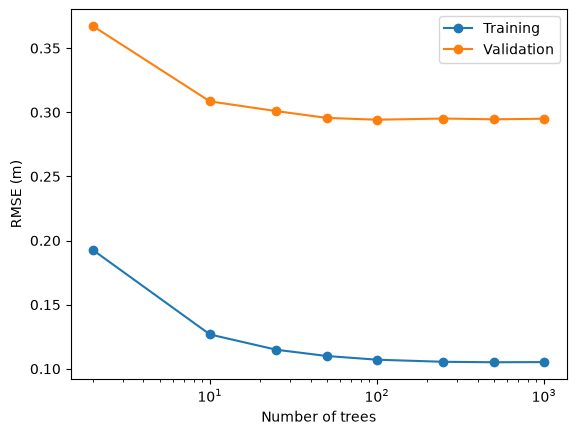

In [15]:
counts = [2, 10, 25, 50, 100, 250, 500, 1000]
train_errors = []
val_errors = []
for n in counts:
    model = RandomForestRegressor(n_estimators=n, random_state=42)
    model.fit(X_train, y_train)
    train_errors.append(np.sqrt(mean_squared_error(y_train, model.predict(X_train))))
    val_errors.append(np.sqrt(mean_squared_error(y_val, model.predict(X_val))))
plt.semilogx(counts, train_errors, "o-", label="Training")
plt.semilogx(counts, val_errors, "o-", label="Validation")
plt.xlabel("Number of trees")
plt.ylabel("RMSE (m)")
plt.legend()
plt.show()

5. decrease as tree increases. but increasae became smaller after 100. 

6. There is a gap between training and validation. but the gap did not increase significantly so no. 